We build an equal-weight benchmark from the 100 A-share codes in our company list. We check the A-share listing date with EastMoney and use adjusted daily prices from Tencent. We keep 82 companies that were listed before 2016. The other 18 were listed later.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'inputs/china_benchmark').exists())
folder = root / 'inputs/china_benchmark'

listings = pd.read_csv(folder / 'listing_screen.csv', dtype={'code': str}, keep_default_na=False)
prices = pd.read_csv(folder / 'prices.csv', dtype={'code': str}, parse_dates=['date'])
calendar = pd.DatetimeIndex(pd.read_csv(folder / 'market_calendar.csv', parse_dates=['date']).date)
coverage = pd.read_csv(folder / 'annual_coverage.csv', dtype={'code': str})

display(listings.groupby('status').size().rename('Companies').to_frame())

,Companies
status,
eligible_listing,82
excluded_listing,18


We use the original listing date for each A-share code. The cutoff is 31 December 2015. This means the basket can start from the first trading day of 2016. These are mainland shares. Some of the companies also have shares in Hong Kong, but we do not use those shares here.

In [3]:
cutoff = '2015-12-31'

eligible = listings.loc[listings.listing_date.le(cutoff)].copy()
excluded = listings.loc[listings.listing_date.gt(cutoff)].copy()
assert len(listings) == 100 and listings.code.nunique() == 100
assert coverage.status.eq('ok').all()
assert set(prices.code) == set(eligible.code)
assert not prices.duplicated(['code', 'date']).any()
assert np.isfinite(prices.adjusted_close).all() and prices.adjusted_close.gt(0).all()
assert prices.groupby('code').date.max().eq(calendar.max()).all()

display(eligible[['code', 'name_en', 'listing_date']].reset_index(drop=True))

,code,name_en,listing_date
0,002371,"NAURA Technology Group Co.,Ltd.",2010-03-16
1,002422,"Sichuan Kelun Pharmaceutical Co., Ltd.",2010-06-03
2,600276,"Jiangsu Hengrui Pharmaceuticals Co.,Ltd.",2000-10-18
3,600519,"Kweichow Moutai Co.,Ltd.",2001-08-27
4,300059,"East Money Information Co.,Ltd.",2010-03-19
...,...,...,...
77,300476,"Victory Giant Technology (HuiZhou)Co.,Ltd.",2015-06-11
78,000807,"Yunnan Aluminium Co.,Ltd.",1998-04-08
79,300308,"Zhongji Innolight Co.,Ltd.",2012-04-10
80,000338,"Weichai Power Co., Ltd.",2007-04-30


In [4]:
display(excluded[['code', 'name_en', 'listing_date']].reset_index(drop=True))

,code,name_en,listing_date
0,601728,China Telecom Corporation Limited,2021-08-20
1,688981,SEMICONDUCTOR MANUFACTURING INTERNATIONAL CORP...,2020-07-16
2,300760,"Shenzhen Mindray Bio-Medical Electronics Co., ...",2018-10-16
3,688271,"Shanghai United Imaging Healthcare Co., Ltd.",2022-08-22
4,688111,"Beijing Kingsoft Office Software, Inc.",2019-11-18
5,600941,China Mobile Limited,2022-01-05
6,688012,Advanced Micro-Fabrication Equipment Inc. China,2019-07-22
7,603259,"WuXi AppTec Co., Ltd.",2018-05-08
8,601816,"Beijing-Shanghai High Speed Railway Co.,Ltd",2020-01-16
9,300750,"Contemporary Amperex Technology Co., Ltd.",2018-06-11


We start with CNY 100,000 at the close on 31 December 2015. Each stock receives 1/82 of the basket. We reset the weights at each month-end close. The new weights apply to the following trading day. Inside each month, the weights move with the prices. The benchmark is long only and does not include trading costs.

In [5]:
class BenchmarkError(ValueError):
    pass


def equal_weight_basket(observations, calendar, codes, start, end, initial_value=100000.0):
    codes = list(codes)
    if not codes or len(set(codes)) != len(codes):
        raise BenchmarkError("The basket needs unique stock codes.")
    if not np.isfinite(initial_value) or initial_value <= 0:
        raise BenchmarkError("The starting value must be positive.")
    data = observations.copy()
    data["date"] = pd.to_datetime(data["date"], errors="raise")
    data["code"] = data["code"].astype(str).str.zfill(6)
    data = data.loc[data.code.isin(codes)]
    data["adjusted_close"] = pd.to_numeric(data["adjusted_close"], errors="raise")
    if data.duplicated(["date", "code"]).any():
        raise BenchmarkError("A stock has duplicate prices on the same date.")
    if not np.isfinite(data.adjusted_close).all() or data.adjusted_close.le(0).any():
        raise BenchmarkError("Adjusted prices must be positive and finite.")
    calendar = pd.DatetimeIndex(pd.to_datetime(calendar)).sort_values().unique()
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    before = calendar[calendar < start]
    dates = calendar[(calendar >= start) & (calendar <= end)]
    if not len(before) or not len(dates):
        raise BenchmarkError("The calendar needs a starting valuation and test dates.")
    base_date = before[-1]
    dates = pd.DatetimeIndex([base_date]).append(dates)
    raw_prices = data.pivot(index="date", columns="code", values="adjusted_close").reindex(columns=codes)
    all_dates = raw_prices.index.union(dates).sort_values()
    prices = raw_prices.reindex(all_dates).ffill().reindex(dates)
    if prices.isna().any().any():
        missing = prices.columns[prices.isna().any()].tolist()
        raise BenchmarkError("Prices are missing before the start for: " + ", ".join(missing))
    observed = raw_prices.reindex(dates).notna()
    carried = ~observed
    target = np.full(len(codes), 1.0 / len(codes))
    weights = target.copy()
    value = float(initial_value)
    values = [value]
    weight_rows = [weights.copy()]
    rebalance_rows = [{"date": base_date, "stock_count": len(codes), "carried_quotes": int(carried.iloc[0].sum())}]
    returns = prices.pct_change(fill_method=None)
    for position in range(1, len(dates)):
        changes = returns.iloc[position].to_numpy(dtype=float)
        portfolio_return = float(weights @ changes)
        value *= 1 + portfolio_return
        weights *= 1 + changes
        weights /= 1 + portfolio_return
        if position < len(dates) - 1 and dates[position].to_period("M") != dates[position + 1].to_period("M"):
            weights = target.copy()
            rebalance_rows.append({"date": dates[position], "stock_count": len(codes), "carried_quotes": int(carried.iloc[position].sum())})
        values.append(value)
        weight_rows.append(weights.copy())
    curve = pd.DataFrame({"benchmark_value": values}, index=dates).rename_axis("date")
    holdings = pd.DataFrame(weight_rows, index=dates, columns=codes).rename_axis("date")
    gaps = []
    for code in codes:
        streak, longest = 0, 0
        for missing in carried[code]:
            streak = streak + 1 if missing else 0
            longest = max(longest, streak)
        stock = data.loc[data.code.eq(code)].sort_values("date")
        gaps.append({
            "code": code,
            "first_quote": stock.date.min().date().isoformat(),
            "last_quote": stock.loc[stock.date.le(end), "date"].max().date().isoformat(),
            "observed_dates": int(observed[code].sum()),
            "carried_dates": int(carried[code].sum()),
            "longest_gap": longest,
        })
    return curve, holdings, pd.DataFrame(rebalance_rows), pd.DataFrame(gaps)


In [6]:
start = '2016-01-01'
end = calendar.max().strftime('%Y-%m-%d')
initial_value = 100000.0

curve, weights, rebalances, gaps = equal_weight_basket(prices, calendar, eligible.code, start, end, initial_value)
assert np.allclose(weights.sum(axis=1), 1)
assert np.allclose(weights.loc[rebalances.date], 1 / len(eligible))

saved = pd.read_csv(root / 'dashboard/china_benchmark_results/portfolio_values.csv', parse_dates=['date']).set_index('date')
pd.testing.assert_frame_equal(curve, saved, check_exact=False, rtol=1e-10)

display(pd.DataFrame({'Start': [curve.index[1].date()], 'End': [curve.index[-1].date()], 'Companies': [len(eligible)], 'Trading days': [len(curve) - 1], 'Monthly resets': [len(rebalances) - 1]}))

,Start,End,Companies,Trading days,Monthly resets
0,2016-01-04,2026-10-16,82,2618,129


We use one market calendar for every stock. On days without a quote, we carry the last available price. We do not fill a missing starting price with a future price. This keeps the same 82 companies in the basket. The monthly reset is an index calculation, so it does not mean that we could trade a suspended stock at its last price.

In [7]:
gap_table = gaps.merge(eligible[['code', 'name_en']], on='code', validate='one_to_one')
display(gap_table.nlargest(10, 'longest_gap')[['code', 'name_en', 'carried_dates', 'longest_gap', 'last_quote']].reset_index(drop=True))

,code,name_en,carried_dates,longest_gap,last_quote
0,000792,"QINGHAI YANHU INDUSTRY CO.,LTD.",319,311,2026-10-16
1,601727,Shanghai Electric Group Company Limited,217,162,2026-10-16
2,002625,"Kuang-Chi Technologies Co., Ltd.",163,153,2026-10-16
3,300308,"Zhongji Innolight Co.,Ltd.",144,139,2026-10-16
4,000651,"GREE ELECTRIC APPLIANCES,INC.OF ZHUHAI",157,135,2026-10-16
5,000002,"CHINA VANKE CO., LTD.",127,122,2026-10-16
6,600309,"Wanhua Chemical Group Co.,Ltd.",125,119,2026-10-16
7,600150,China CSSC Holdings Limited,141,114,2026-10-16
8,000538,"YUNNAN BAIYAO GROUP CO.,LTD",164,111,2026-10-16
9,601600,ALUMINUM CORPORATION OF CHINA LIMITED,109,108,2026-10-16


In [8]:
def basket_metrics(curve):
    values = curve["benchmark_value"]
    changes = values.pct_change(fill_method=None).dropna()
    years = (values.index[-1] - values.index[0]).days / 365.25
    if years <= 0 or len(changes) < 2:
        raise BenchmarkError("The benchmark needs at least two return observations.")
    return {
        "initial_value": float(values.iloc[0]),
        "final_value": float(values.iloc[-1]),
        "total_return": float((values.iloc[-1] / values.iloc[0] - 1) * 100),
        "annual_return": float(((values.iloc[-1] / values.iloc[0]) ** (1 / years) - 1) * 100),
        "volatility": float(changes.std(ddof=1) * np.sqrt(252) * 100),
        "drawdown": float((values / values.cummax() - 1).min() * 100),
    }


metrics = basket_metrics(curve)
display(pd.Series(metrics).rename('Result').to_frame().round(2))

,Result
initial_value,100000.00
final_value,462802.32
total_return,362.80
annual_return,15.25
volatility,18.69
drawdown,-25.03


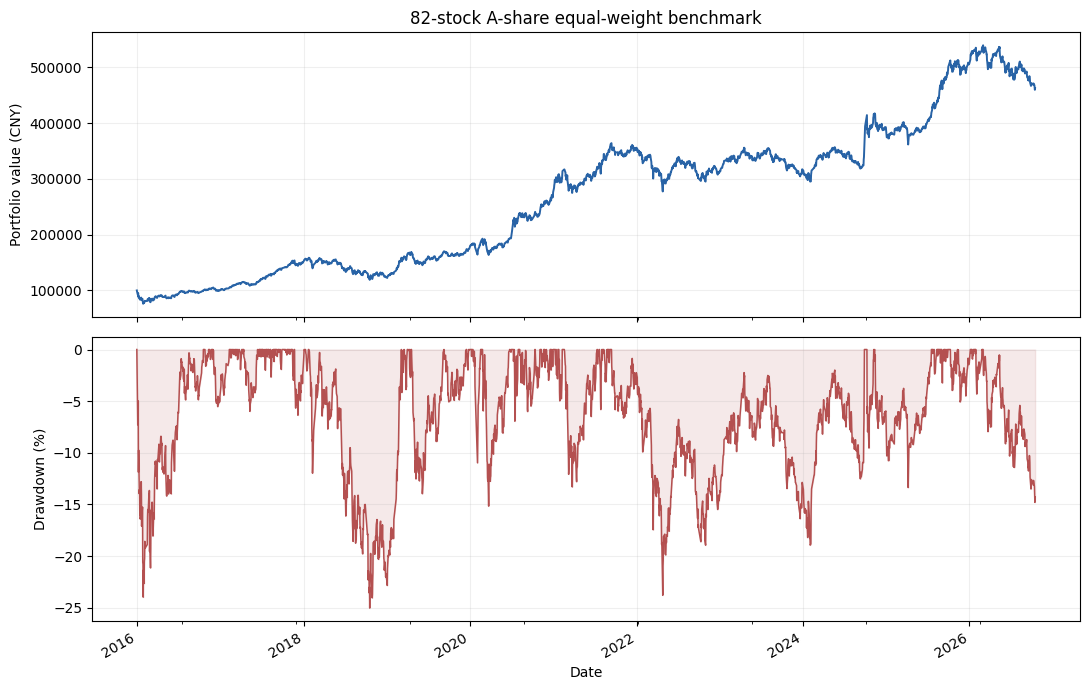

In [9]:
figure_size = (11, 7)

fig, axes = plt.subplots(2, 1, figsize=figure_size, sharex=True)
curve.benchmark_value.plot(ax=axes[0], color='#2863a6', linewidth=1.4)
axes[0].set_title('82-stock A-share equal-weight benchmark')
axes[0].set_ylabel('Portfolio value (CNY)')
axes[0].ticklabel_format(axis='y', style='plain')
drawdown = (curve.benchmark_value / curve.benchmark_value.cummax() - 1) * 100
drawdown.plot(ax=axes[1], color='#b45050', linewidth=1.1)
axes[1].fill_between(drawdown.index, drawdown, 0, color='#b45050', alpha=0.12)
axes[1].set_ylabel('Drawdown (%)')
axes[1].set_xlabel('Date')
for axis in axes:
    axis.grid(alpha=0.2)
fig.tight_layout()
plt.show()

The basket grew from CNY 100,000 to CNY 462,802 between the starting close and 16 October 2026. Its total return was 362.80%, and the annual return was 15.25%. The largest fall from a previous high was 25.03%. We reset the weights 129 times after the first allocation. This gives us a wider benchmark for our factor research. These results are before costs and use the same company list across the full period.

We selected the companies today and then looked at their past prices. This is a research basket, not the historical membership of a published index. Tencent's backward-adjusted prices are return proxies; we did not build a separate dividend-reinvestment series. We also did not apply a separate historical size or liquidity screen. The full listing check, daily prices, coverage checks and source records are saved in inputs/china_benchmark.